# Various estimates for the PRACE proposal

In [1]:
%load_ext autoreload
%autoreload 2
%pylab inline

Populating the interactive namespace from numpy and matplotlib


## Functions that implement the standard MMSN relations

In [2]:
def h_scale(r):
    return 0.034*r**1.25
def c_sound(r):
    v_K=30/r**0.5
    return v_K*h_scale(r)/r

## 10-100 AU experiment

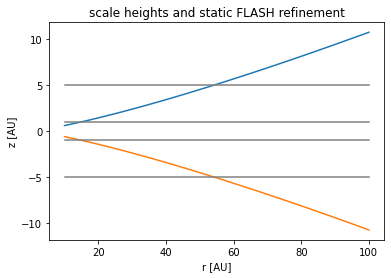

In [19]:
r=logspace(1,2)
H=h_scale(r)
Plot=plot
Plot(r,H)
Plot(r,-H);
r=[10,100]
c='grey'
h=1; plot(r,[h,h],color=c); plot(r,[-h,-h],color=c)
h=5; plot(r,[h,h],color=c); plot(r,[-h,-h],color=c)
xlabel('r [AU]'); ylabel('z [AU]')
title('scale heights and static FLASH refinement');

### Sum the number of updates over all shells

In [4]:
import astropy.units as U
import astropy.constants as C

def estimates(r0=10,r1=100,n=16,N_h=2.2,n_h=30,Courant=0.27,grant_Mch=40):
    
    print('With {} cells per scale height, {} per patch, covering r=[{},{}] and 2x{} H:'
          .format(n_h,n,r0,r1,N_h))
    dlnr=1/n
    s=r0*dlnr
    print('The patch size must be at most {:.3f} AU for single cell tilt'.format(s))
    H=h_scale(r0)
    ds=H/n_h
    s=n*ds
    dlnr=s/r0
    print('The actual patch size is {:.3f} AU, with dlnr={:.3f}'.format(s,dlnr))
    H=h_scale(r0)
    N_z=int(2*N_h*H/s+1)
    print('The initial number of patches vertically is {}, covering {:.2f} scale heights'
          .format(N_z,N_z*s/H))
    N_r=int(log(r1/r0)/dlnr+1)
    print('The number of radial cylinder shells is {}'.format(N_r))
    N_phi=int(2*pi/dlnr+1)
    print('The number of patches in the phi-direction is {}'.format(N_phi))
    N_tot=N_z*N_r*N_phi
    print('The total number of patches is {}, corresponding to a {}-cubed uni-grid simulation'
          .format(N_tot,int(N_tot**0.3333*n)))
    n_core=N_tot/50
    cores_per_node=48
    n_node=int(n_core/cores_per_node)
    print('The number of {}-core nodes must be at most {} for good performance'
         .format(cores_per_node,n_node))
    Mch=n_core*24*365/1e6
    print('The number of Mch per year for the max job size is {:.1f}'.format(Mch))
    v_K=30./r0**0.5
    print('The Kepler speed at {} AU is {:.1f} km/s'.format(r0,v_K))
    c_s=c_sound(r0)
    print('The sound speed at {} AU is {:.2f} km/s'.format(r0,c_s))
    AU=C.au.cgs.value
    yr=U.yr.cgs/U.s
    dt=Courant*ds*AU/c_s/yr
    print('The time step at Courant number {:.2f} is {:.3f} yr'.format(Courant,dt))
    orbit=r0**1.5
    print('The inner orbit time is {:.1f} yr'.format(orbit))
    n_orbit=orbit/dt
    N_update=N_r*N_phi*N_z*n_orbit
    print('The number of time steps at inner orbit per orbit is {:.0f}'.format(n_orbit))
    def n_updates(r0,r1):
        """ Compute number of patch updates in the r0-r1 interval """
        n_update=0
        inner_orbit_yr=r0**1.5
        for i in range(N_r):
            r=r0*exp(i*dlnr)
            v_K=30./r**0.5
            c_s=c_sound(r)
            ds=h_scale(r)/n_h
            ds=r*dlnr/n
            dt_yr=Courant*ds*AU/c_s/yr
            n_step=inner_orbit_yr/dt_yr
            n_update+=n_step
        return n_update
    n_ring=n_updates(r0,r1)
    bins=5
    particles_per_bin=5
    microsec_per_cell=0.7+0.07*particles_per_bin*bins
    orbit_hr=microsec_per_cell*1e-6/3600*n**3*N_z*N_phi*n_ring
    print('The number of core-hours per inner orbit is {:.1f}'.format(orbit_hr))
    constant_dt_hr=microsec_per_cell*1e-6/3600*n**3*N_z*N_phi*N_r*n_orbit
    print('The number of core-hours with constant dt would be {:.1f}'.format(constant_dt_hr))
    orbit_Mch=1e6/orbit_hr
    print('The number of inner orbits per Mch is {:.1f}'.format(orbit_Mch))
    orbit_grant=grant_Mch*orbit_Mch
    print('The number of inner orbits for a {} Mch grant is {:.0f}'.format(grant_Mch,orbit_grant))
    outer_orbit_grant=grant_Mch*orbit_Mch*(r0/r1)**1.5
    print('The number of outer orbits for a {} Mch grant is {:.0f}'.format(grant_Mch,outer_orbit_grant))
    total_yr=orbit_grant*r0**1.5/1e6
    print('The number of Myr for a {} Mch grant is {:.1f}'.format(grant_Mch,total_yr))
estimates()

With 30 cells per scale height, 16 per patch, covering r=[10,100] and 2x2.2 H:
The patch size must be at most 0.625 AU for single cell tilt
The actual patch size is 0.322 AU, with dlnr=0.032
The initial number of patches vertically is 9, covering 4.80 scale heights
The number of radial cylinder shells is 72
The number of patches in the phi-direction is 195
The total number of patches is 126360, corresponding to a 802-cubed uni-grid simulation
The number of 48-core nodes must be at most 52 for good performance
The number of Mch per year for the max job size is 22.1
The Kepler speed at 10 AU is 9.5 km/s
The sound speed at 10 AU is 0.57 km/s
The time step at Courant number 0.27 is 141921001357.010 3.16881e-08 yr
The inner orbit time is 31.6 yr
The number of time steps at inner orbit per orbit is 0 3.15576e+07
The number of core-hours per inner orbit is 0.0
The number of core-hours with constant dt would be 0.0 3.15576e+07
The number of inner orbits per Mch is 1215152856.5
The number of in

## MMSN accretion velocity

In [5]:
import astropy.units as U
import astropy.constants as C

def sigma_MMSN(r):
    """ Mass density per unit area for MMSN """
    return 1700*U.g.cgs/U.cm.cgs**2/r**1.5

def v_accr_MMSN(r,mdot_yr):
    """ mdot is mass per unit time. To obtain velocity, divide with sigma, which
        gives area per unit time, and divide with the circumference 2*pi*r """
    mdot=mdot_yr*C.M_sun.cgs/U.yr.cgs
    v=mdot/(sigma_MMSN(r)*2*pi*r*C.au.cgs)
    return v.decompose()

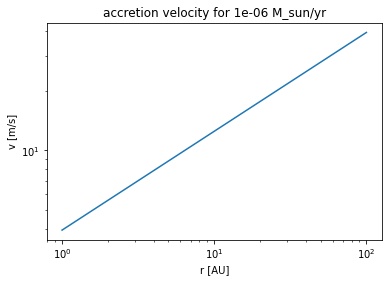

In [12]:
r=logspace(0,2)
rate=1e-6
loglog(r,v_accr_MMSN(r,1e-6))
xlabel('r [AU]'); ylabel('v [m/s]'); title('accretion velocity for {} M_sun/yr'.format(rate));

## Expontial accretion rate profiles

If we assume that the accretion rate has the functional form
$$
\dot{\rm m}(t) = \dot{\rm m}(0) ~ e^{-t/t_a}
$$
and the final mass is $M$, then the mass is
$$
M(t) = M(\infty) ~ (1-e^{-t/t_a})
$$
and
$$
M(\infty) = \dot{\rm m}(0) ~ t_a
$$
The time when $\dot{\rm m}(t) = \dot{\rm m}_1$ then satisfies
$$
M/t_a  ~ e^{-t_1/t_a} = \dot{\rm m}_1
$$
with solution
$$
t_1 = t_a \ln \left(\frac{M}{\dot{\rm m}_1 t_a} \right) = t_a \ln \left(\frac {\dot{\rm m}_0} {\dot{\rm m}_1} \right)
$$

A MMSN with accretion rate $10^{-8}$ would have a disk replenishement time of 3 Myr.  This is probably an unreaslitic combination of disk mass and accretion rate

In [7]:
mdot_yr=1e-8
t_repl=0.03/mdot_yr
t_repl/1e6

3.0

## Accretion time scale considerations
There are in principle two types of solution extremes:  One has shorter accretion decay time than the disk replenishment time, while the other one has shorter disk replenishment time than accretion decay time.

Only the latter is consistent with a power law dependence of surface density with radius; the first one would lead to a time dependent disk density profile, unless the viscosity profile satisfied a very particular shape requirement.

To preserve an approximate power law density distribution in the former case would require that the mass accretion rate had a very peculiar radial depenence.  The differential mass distribution in an MMSN disk is $\frac{dM}{dr} \sim r^{-1/2}$

If the disc accretion velocity is independent of the disk mass the disk replenishment time is smaller than the accretion rate decay time, by the ratio of disk mass to stell mass.  Hence for the MMSN, the disk replenishment time is typically 30 times smaller than the disk age.
